In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

from six.moves import urllib

from sqlalchemy import create_engine
import plotly.express as px

import os
import warnings
warnings.filterwarnings("ignore")


In [2]:
data_dir="./data/"
data_url = "https://raw.githubusercontent.com/mohitmahiyt/cardataset/refs/heads/main/cars_dataset.csv"
os.makedirs(data_dir, exist_ok=True)

filename = os.path.basename(data_url)
print(filename)

filepath = os.path.join(data_dir,filename)
print(filepath)

urllib.request.urlretrieve(data_url, filepath)

cars_dataset.csv
./data/cars_dataset.csv


('./data/cars_dataset.csv', <http.client.HTTPMessage at 0x24414b28370>)

In [3]:
# data cleaning

In [4]:
df = pd.read_csv("./data/cars_dataset.csv")
df

,car data set,NaN,NaN.1,NaN.2,NaN.3,NaN.4,NaN.5,NaN.6,NaN.7,NaN.8,NaN.9,NaN.10,NaN.11,NaN.12,Unnamed: 14
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15807,30016.0,Bentley Continental,Bentley,Continental,10,30000,Dealer,Petrol,Automatic,8.6,5998,552,4,8100000,NaN
15808,30017.0,Rolls-Royce Ghost,Rolls-Royce,Ghost,4,5000,Individual,Petrol,Automatic,10.2,6592,563,4,24200000,NaN
15809,30018.0,Bentley Continental,Bentley,Continental,9,37500,Dealer,Petrol,Automatic,6,5998,600,5,5200000,NaN
15810,30019.0,Ferrari GTC4Lusso,Ferrari,GTC4Lusso,2,3800,Dealer,Petrol,Automatic,4,3855,601,4,39500000,NaN


In [5]:
df.head(30)

,car data set,NaN,NaN.1,NaN.2,NaN.3,NaN.4,NaN.5,NaN.6,NaN.7,NaN.8,NaN.9,NaN.10,NaN.11,NaN.12,Unnamed: 14
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
df = pd.read_csv("./data/cars_dataset.csv", header=11)
df

,NaN,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price,my_car
0,1.0,Maruti Alto,Maruti,Alto,9.0,53800.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,235000.0,NaN
1,2.0,Maruti Alto,Maruti,Alto,11.0,11000.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,185000.0,NaN
2,3.0,Maruti Alto,Maruti,Alto,11.0,80000.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,150000.0,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15796,30016.0,Bentley Continental,Bentley,Continental,10.0,30000.0,Dealer,Petrol,Automatic,8.60,5998.0,552.0,4.0,8100000.0,NaN
15797,30017.0,Rolls-Royce Ghost,Rolls-Royce,Ghost,4.0,5000.0,Individual,Petrol,Automatic,10.20,6592.0,563.0,4.0,24200000.0,NaN
15798,30018.0,Bentley Continental,Bentley,Continental,9.0,37500.0,Dealer,Petrol,Automatic,6.00,5998.0,600.0,5.0,5200000.0,NaN
15799,30019.0,Ferrari GTC4Lusso,Ferrari,GTC4Lusso,2.0,3800.0,Dealer,Petrol,Automatic,4.00,3855.0,601.0,4.0,39500000.0,NaN


In [7]:
df.isnull().sum()

NaN                    390
car_name               390
brand                  390
model                  390
vehicle_age            390
km_driven              390
seller_type            390
fuel_type              390
transmission_type      390
mileage                390
engine                 390
max_power              390
seats                  390
selling_price          390
 my_car              15801
dtype: int64

In [8]:
df.columns

Index(['NaN', 'car_name', 'brand', 'model', 'vehicle_age', 'km_driven',
       'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine',
       'max_power', 'seats', 'selling_price', ' my_car'],
      dtype='object')

In [9]:
df

,NaN,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price,my_car
0,1.0,Maruti Alto,Maruti,Alto,9.0,53800.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,235000.0,NaN
1,2.0,Maruti Alto,Maruti,Alto,11.0,11000.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,185000.0,NaN
2,3.0,Maruti Alto,Maruti,Alto,11.0,80000.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,150000.0,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15796,30016.0,Bentley Continental,Bentley,Continental,10.0,30000.0,Dealer,Petrol,Automatic,8.60,5998.0,552.0,4.0,8100000.0,NaN
15797,30017.0,Rolls-Royce Ghost,Rolls-Royce,Ghost,4.0,5000.0,Individual,Petrol,Automatic,10.20,6592.0,563.0,4.0,24200000.0,NaN
15798,30018.0,Bentley Continental,Bentley,Continental,9.0,37500.0,Dealer,Petrol,Automatic,6.00,5998.0,600.0,5.0,5200000.0,NaN
15799,30019.0,Ferrari GTC4Lusso,Ferrari,GTC4Lusso,2.0,3800.0,Dealer,Petrol,Automatic,4.00,3855.0,601.0,4.0,39500000.0,NaN


In [10]:
df.drop(' my_car', axis=1, inplace=True)

In [11]:
df

,NaN,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,1.0,Maruti Alto,Maruti,Alto,9.0,53800.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,235000.0
1,2.0,Maruti Alto,Maruti,Alto,11.0,11000.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,185000.0
2,3.0,Maruti Alto,Maruti,Alto,11.0,80000.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,150000.0
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15796,30016.0,Bentley Continental,Bentley,Continental,10.0,30000.0,Dealer,Petrol,Automatic,8.60,5998.0,552.0,4.0,8100000.0
15797,30017.0,Rolls-Royce Ghost,Rolls-Royce,Ghost,4.0,5000.0,Individual,Petrol,Automatic,10.20,6592.0,563.0,4.0,24200000.0
15798,30018.0,Bentley Continental,Bentley,Continental,9.0,37500.0,Dealer,Petrol,Automatic,6.00,5998.0,600.0,5.0,5200000.0
15799,30019.0,Ferrari GTC4Lusso,Ferrari,GTC4Lusso,2.0,3800.0,Dealer,Petrol,Automatic,4.00,3855.0,601.0,4.0,39500000.0


In [12]:
df.isnull().sum()

NaN                  390
car_name             390
brand                390
model                390
vehicle_age          390
km_driven            390
seller_type          390
fuel_type            390
transmission_type    390
mileage              390
engine               390
max_power            390
seats                390
selling_price        390
dtype: int64

In [13]:
df

,NaN,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,1.0,Maruti Alto,Maruti,Alto,9.0,53800.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,235000.0
1,2.0,Maruti Alto,Maruti,Alto,11.0,11000.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,185000.0
2,3.0,Maruti Alto,Maruti,Alto,11.0,80000.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,150000.0
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15796,30016.0,Bentley Continental,Bentley,Continental,10.0,30000.0,Dealer,Petrol,Automatic,8.60,5998.0,552.0,4.0,8100000.0
15797,30017.0,Rolls-Royce Ghost,Rolls-Royce,Ghost,4.0,5000.0,Individual,Petrol,Automatic,10.20,6592.0,563.0,4.0,24200000.0
15798,30018.0,Bentley Continental,Bentley,Continental,9.0,37500.0,Dealer,Petrol,Automatic,6.00,5998.0,600.0,5.0,5200000.0
15799,30019.0,Ferrari GTC4Lusso,Ferrari,GTC4Lusso,2.0,3800.0,Dealer,Petrol,Automatic,4.00,3855.0,601.0,4.0,39500000.0


In [14]:
df[df.isna().all(axis=1)]

,NaN,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1046,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1047,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1075,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1113,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
df.dropna(how='all', inplace=True)

In [16]:
df

,NaN,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,1.0,Maruti Alto,Maruti,Alto,9.0,53800.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,235000.0
1,2.0,Maruti Alto,Maruti,Alto,11.0,11000.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,185000.0
2,3.0,Maruti Alto,Maruti,Alto,11.0,80000.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,150000.0
7,4.0,Maruti Alto,Maruti,Alto,10.0,57000.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,172000.0
8,5.0,Maruti Alto,Maruti,Alto,11.0,72000.0,Individual,CNG,Manual,26.83,796.0,38.4,5.0,125000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15796,30016.0,Bentley Continental,Bentley,Continental,10.0,30000.0,Dealer,Petrol,Automatic,8.60,5998.0,552.0,4.0,8100000.0
15797,30017.0,Rolls-Royce Ghost,Rolls-Royce,Ghost,4.0,5000.0,Individual,Petrol,Automatic,10.20,6592.0,563.0,4.0,24200000.0
15798,30018.0,Bentley Continental,Bentley,Continental,9.0,37500.0,Dealer,Petrol,Automatic,6.00,5998.0,600.0,5.0,5200000.0
15799,30019.0,Ferrari GTC4Lusso,Ferrari,GTC4Lusso,2.0,3800.0,Dealer,Petrol,Automatic,4.00,3855.0,601.0,4.0,39500000.0


In [17]:
df.isnull().sum()

NaN                  0
car_name             0
brand                0
model                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            0
seats                0
selling_price        0
dtype: int64

In [18]:
df

,NaN,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,1.0,Maruti Alto,Maruti,Alto,9.0,53800.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,235000.0
1,2.0,Maruti Alto,Maruti,Alto,11.0,11000.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,185000.0
2,3.0,Maruti Alto,Maruti,Alto,11.0,80000.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,150000.0
7,4.0,Maruti Alto,Maruti,Alto,10.0,57000.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,172000.0
8,5.0,Maruti Alto,Maruti,Alto,11.0,72000.0,Individual,CNG,Manual,26.83,796.0,38.4,5.0,125000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15796,30016.0,Bentley Continental,Bentley,Continental,10.0,30000.0,Dealer,Petrol,Automatic,8.60,5998.0,552.0,4.0,8100000.0
15797,30017.0,Rolls-Royce Ghost,Rolls-Royce,Ghost,4.0,5000.0,Individual,Petrol,Automatic,10.20,6592.0,563.0,4.0,24200000.0
15798,30018.0,Bentley Continental,Bentley,Continental,9.0,37500.0,Dealer,Petrol,Automatic,6.00,5998.0,600.0,5.0,5200000.0
15799,30019.0,Ferrari GTC4Lusso,Ferrari,GTC4Lusso,2.0,3800.0,Dealer,Petrol,Automatic,4.00,3855.0,601.0,4.0,39500000.0


In [19]:
df.drop('NaN',axis=1, inplace=True)

In [20]:
df

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti Alto,Maruti,Alto,9.0,53800.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,235000.0
1,Maruti Alto,Maruti,Alto,11.0,11000.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,185000.0
2,Maruti Alto,Maruti,Alto,11.0,80000.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,150000.0
7,Maruti Alto,Maruti,Alto,10.0,57000.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,172000.0
8,Maruti Alto,Maruti,Alto,11.0,72000.0,Individual,CNG,Manual,26.83,796.0,38.4,5.0,125000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
15796,Bentley Continental,Bentley,Continental,10.0,30000.0,Dealer,Petrol,Automatic,8.60,5998.0,552.0,4.0,8100000.0
15797,Rolls-Royce Ghost,Rolls-Royce,Ghost,4.0,5000.0,Individual,Petrol,Automatic,10.20,6592.0,563.0,4.0,24200000.0
15798,Bentley Continental,Bentley,Continental,9.0,37500.0,Dealer,Petrol,Automatic,6.00,5998.0,600.0,5.0,5200000.0
15799,Ferrari GTC4Lusso,Ferrari,GTC4Lusso,2.0,3800.0,Dealer,Petrol,Automatic,4.00,3855.0,601.0,4.0,39500000.0


In [21]:
df.reset_index(drop=True, inplace=True)

In [22]:
df

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti Alto,Maruti,Alto,9.0,53800.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,235000.0
1,Maruti Alto,Maruti,Alto,11.0,11000.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,185000.0
2,Maruti Alto,Maruti,Alto,11.0,80000.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,150000.0
3,Maruti Alto,Maruti,Alto,10.0,57000.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,172000.0
4,Maruti Alto,Maruti,Alto,11.0,72000.0,Individual,CNG,Manual,26.83,796.0,38.4,5.0,125000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
15406,Bentley Continental,Bentley,Continental,10.0,30000.0,Dealer,Petrol,Automatic,8.60,5998.0,552.0,4.0,8100000.0
15407,Rolls-Royce Ghost,Rolls-Royce,Ghost,4.0,5000.0,Individual,Petrol,Automatic,10.20,6592.0,563.0,4.0,24200000.0
15408,Bentley Continental,Bentley,Continental,9.0,37500.0,Dealer,Petrol,Automatic,6.00,5998.0,600.0,5.0,5200000.0
15409,Ferrari GTC4Lusso,Ferrari,GTC4Lusso,2.0,3800.0,Dealer,Petrol,Automatic,4.00,3855.0,601.0,4.0,39500000.0


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15411 entries, 0 to 15410
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   car_name           15411 non-null  object 
 1   brand              15411 non-null  object 
 2   model              15411 non-null  object 
 3   vehicle_age        15411 non-null  float64
 4   km_driven          15411 non-null  float64
 5   seller_type        15411 non-null  object 
 6   fuel_type          15411 non-null  object 
 7   transmission_type  15411 non-null  object 
 8   mileage            15411 non-null  float64
 9   engine             15411 non-null  float64
 10  max_power          15411 non-null  float64
 11  seats              15411 non-null  float64
 12  selling_price      15411 non-null  float64
dtypes: float64(7), object(6)
memory usage: 1.5+ MB


In [24]:
df

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti Alto,Maruti,Alto,9.0,53800.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,235000.0
1,Maruti Alto,Maruti,Alto,11.0,11000.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,185000.0
2,Maruti Alto,Maruti,Alto,11.0,80000.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,150000.0
3,Maruti Alto,Maruti,Alto,10.0,57000.0,Dealer,CNG,Manual,26.83,796.0,38.4,5.0,172000.0
4,Maruti Alto,Maruti,Alto,11.0,72000.0,Individual,CNG,Manual,26.83,796.0,38.4,5.0,125000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
15406,Bentley Continental,Bentley,Continental,10.0,30000.0,Dealer,Petrol,Automatic,8.60,5998.0,552.0,4.0,8100000.0
15407,Rolls-Royce Ghost,Rolls-Royce,Ghost,4.0,5000.0,Individual,Petrol,Automatic,10.20,6592.0,563.0,4.0,24200000.0
15408,Bentley Continental,Bentley,Continental,9.0,37500.0,Dealer,Petrol,Automatic,6.00,5998.0,600.0,5.0,5200000.0
15409,Ferrari GTC4Lusso,Ferrari,GTC4Lusso,2.0,3800.0,Dealer,Petrol,Automatic,4.00,3855.0,601.0,4.0,39500000.0


In [25]:
df.columns

Index(['car_name', 'brand', 'model', 'vehicle_age', 'km_driven', 'seller_type',
       'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power',
       'seats', 'selling_price'],
      dtype='object')

In [26]:
df[['vehicle_age', 'km_driven', 'engine','seats']]=df[['vehicle_age', 'km_driven', 'engine','seats']].astype(int)

In [27]:
df

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti Alto,Maruti,Alto,9,53800,Dealer,CNG,Manual,26.83,796,38.4,5,235000.0
1,Maruti Alto,Maruti,Alto,11,11000,Dealer,CNG,Manual,26.83,796,38.4,5,185000.0
2,Maruti Alto,Maruti,Alto,11,80000,Dealer,CNG,Manual,26.83,796,38.4,5,150000.0
3,Maruti Alto,Maruti,Alto,10,57000,Dealer,CNG,Manual,26.83,796,38.4,5,172000.0
4,Maruti Alto,Maruti,Alto,11,72000,Individual,CNG,Manual,26.83,796,38.4,5,125000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
15406,Bentley Continental,Bentley,Continental,10,30000,Dealer,Petrol,Automatic,8.60,5998,552.0,4,8100000.0
15407,Rolls-Royce Ghost,Rolls-Royce,Ghost,4,5000,Individual,Petrol,Automatic,10.20,6592,563.0,4,24200000.0
15408,Bentley Continental,Bentley,Continental,9,37500,Dealer,Petrol,Automatic,6.00,5998,600.0,5,5200000.0
15409,Ferrari GTC4Lusso,Ferrari,GTC4Lusso,2,3800,Dealer,Petrol,Automatic,4.00,3855,601.0,4,39500000.0


In [28]:
df[df.duplicated(keep=False)]

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
122,Maruti Alto,Maruti,Alto,9,70000,Individual,Petrol,Manual,19.70,796,46.3,5,200000.0
132,Maruti Alto,Maruti,Alto,11,70000,Individual,Petrol,Manual,19.70,796,46.3,5,135000.0
160,Maruti Alto,Maruti,Alto,9,70000,Individual,Petrol,Manual,19.70,796,46.3,5,200000.0
203,Maruti Alto,Maruti,Alto,11,70000,Individual,Petrol,Manual,19.70,796,46.3,5,135000.0
351,Maruti Alto,Maruti,Alto,2,25000,Individual,Petrol,Manual,24.70,796,47.3,5,310000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
15286,BMW 6,BMW,6,3,11000,Dealer,Diesel,Automatic,17.09,2993,261.4,4,5600000.0
15361,BMW 7,BMW,7,13,70000,Dealer,Petrol,Automatic,8.45,2979,321.0,5,750000.0
15364,BMW 7,BMW,7,13,70000,Dealer,Petrol,Automatic,8.45,2979,321.0,5,750000.0
15390,Mercedes-Benz S-Class,Mercedes-Benz,S-Class,13,72000,Dealer,Petrol,Automatic,10.13,3498,364.9,5,999000.0


In [29]:
df.drop_duplicates(inplace=True)

In [30]:
df

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti Alto,Maruti,Alto,9,53800,Dealer,CNG,Manual,26.83,796,38.4,5,235000.0
1,Maruti Alto,Maruti,Alto,11,11000,Dealer,CNG,Manual,26.83,796,38.4,5,185000.0
2,Maruti Alto,Maruti,Alto,11,80000,Dealer,CNG,Manual,26.83,796,38.4,5,150000.0
3,Maruti Alto,Maruti,Alto,10,57000,Dealer,CNG,Manual,26.83,796,38.4,5,172000.0
4,Maruti Alto,Maruti,Alto,11,72000,Individual,CNG,Manual,26.83,796,38.4,5,125000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
15406,Bentley Continental,Bentley,Continental,10,30000,Dealer,Petrol,Automatic,8.60,5998,552.0,4,8100000.0
15407,Rolls-Royce Ghost,Rolls-Royce,Ghost,4,5000,Individual,Petrol,Automatic,10.20,6592,563.0,4,24200000.0
15408,Bentley Continental,Bentley,Continental,9,37500,Dealer,Petrol,Automatic,6.00,5998,600.0,5,5200000.0
15409,Ferrari GTC4Lusso,Ferrari,GTC4Lusso,2,3800,Dealer,Petrol,Automatic,4.00,3855,601.0,4,39500000.0


In [31]:
df.reset_index(drop=True)

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti Alto,Maruti,Alto,9,53800,Dealer,CNG,Manual,26.83,796,38.4,5,235000.0
1,Maruti Alto,Maruti,Alto,11,11000,Dealer,CNG,Manual,26.83,796,38.4,5,185000.0
2,Maruti Alto,Maruti,Alto,11,80000,Dealer,CNG,Manual,26.83,796,38.4,5,150000.0
3,Maruti Alto,Maruti,Alto,10,57000,Dealer,CNG,Manual,26.83,796,38.4,5,172000.0
4,Maruti Alto,Maruti,Alto,11,72000,Individual,CNG,Manual,26.83,796,38.4,5,125000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
15239,Bentley Continental,Bentley,Continental,10,30000,Dealer,Petrol,Automatic,8.60,5998,552.0,4,8100000.0
15240,Rolls-Royce Ghost,Rolls-Royce,Ghost,4,5000,Individual,Petrol,Automatic,10.20,6592,563.0,4,24200000.0
15241,Bentley Continental,Bentley,Continental,9,37500,Dealer,Petrol,Automatic,6.00,5998,600.0,5,5200000.0
15242,Ferrari GTC4Lusso,Ferrari,GTC4Lusso,2,3800,Dealer,Petrol,Automatic,4.00,3855,601.0,4,39500000.0


In [32]:
df.duplicated().sum()

np.int64(0)

In [33]:
df.to_csv("./data/cleaned_cars_dataset.csv", index=False)

# save the data in sql

# EDA

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15244 entries, 0 to 15410
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   car_name           15244 non-null  object 
 1   brand              15244 non-null  object 
 2   model              15244 non-null  object 
 3   vehicle_age        15244 non-null  int64  
 4   km_driven          15244 non-null  int64  
 5   seller_type        15244 non-null  object 
 6   fuel_type          15244 non-null  object 
 7   transmission_type  15244 non-null  object 
 8   mileage            15244 non-null  float64
 9   engine             15244 non-null  int64  
 10  max_power          15244 non-null  float64
 11  seats              15244 non-null  int64  
 12  selling_price      15244 non-null  float64
dtypes: float64(3), int64(4), object(6)
memory usage: 1.6+ MB


In [35]:
# splitting numerical and categorical columns

In [36]:
df['brand'].dtypes

dtype('O')

In [37]:
df['max_power'].dtypes

dtype('float64')

In [38]:
df['seats'].dtypes != 'O'

True

In [39]:
df.columns

Index(['car_name', 'brand', 'model', 'vehicle_age', 'km_driven', 'seller_type',
       'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power',
       'seats', 'selling_price'],
      dtype='object')

In [40]:
numerical_features = [feature for feature in df.columns  if df[feature].dtypes !='O']
categorical_features = [feature for feature in df.columns  if df[feature].dtypes =='O']

print(f"There are {len(numerical_features)} numerical features named: {numerical_features}")
print(f"There are {len(categorical_features)} categorical features named: {categorical_features}")

There are 7 numerical features named: ['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']
There are 6 categorical features named: ['car_name', 'brand', 'model', 'seller_type', 'fuel_type', 'transmission_type']


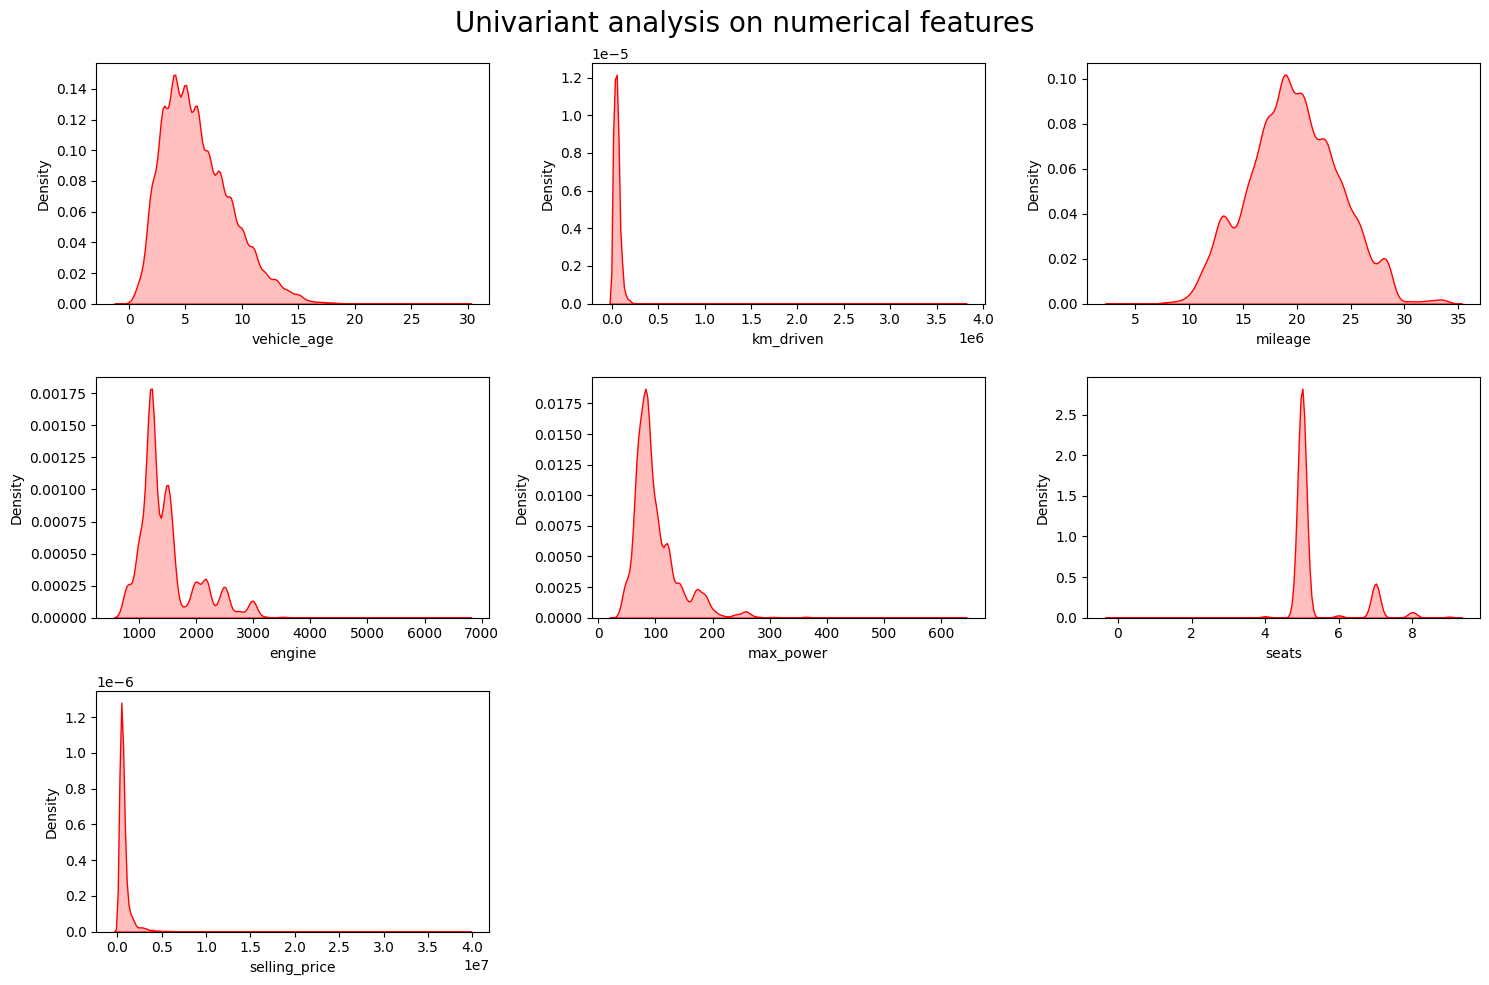

In [41]:
# Univariant Analysis
# numerical features

plt.figure(figsize=(15,10))
plt.suptitle("Univariant analysis on numerical features", fontsize=20)
for i in range(len(numerical_features)):
    plt.subplot(3,3,i+1)
    sns.kdeplot(x = df[numerical_features[i]], shade=True, color='r')
    plt.tight_layout()

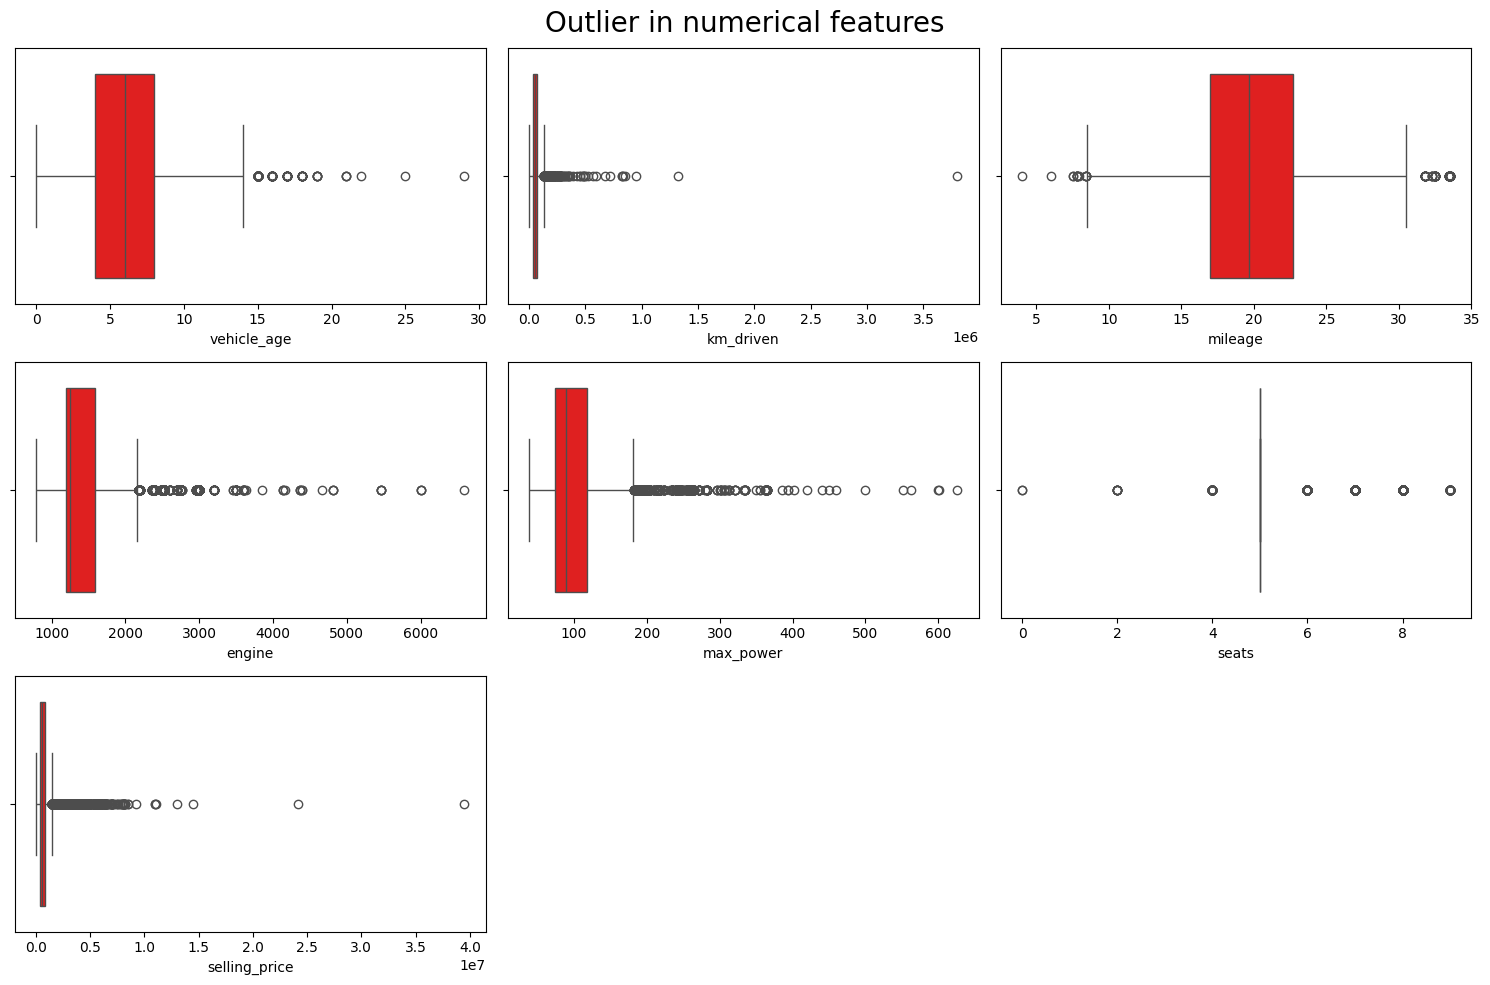

In [42]:
# Outlier detection on numerical features

plt.figure(figsize=(15,10))
plt.suptitle("Outlier in numerical features", fontsize=20)
for i in range(len(numerical_features)):
    plt.subplot(3,3,i+1)
    sns.boxplot(x = df[numerical_features[i]], color='r')
    plt.tight_layout()

connecting to sql


In [43]:
from sqlalchemy import create_engine
engine = create_engine(
    "mysql+pymysql://root:@localhost/carPrediction"
)

df = pd.read_csv(r"data\cleaned_cars_dataset.csv")

df.to_sql(
    'cars',
    engine,
    if_exists='replace',
    index=False
)

print("Table imported successfully")

Table imported successfully


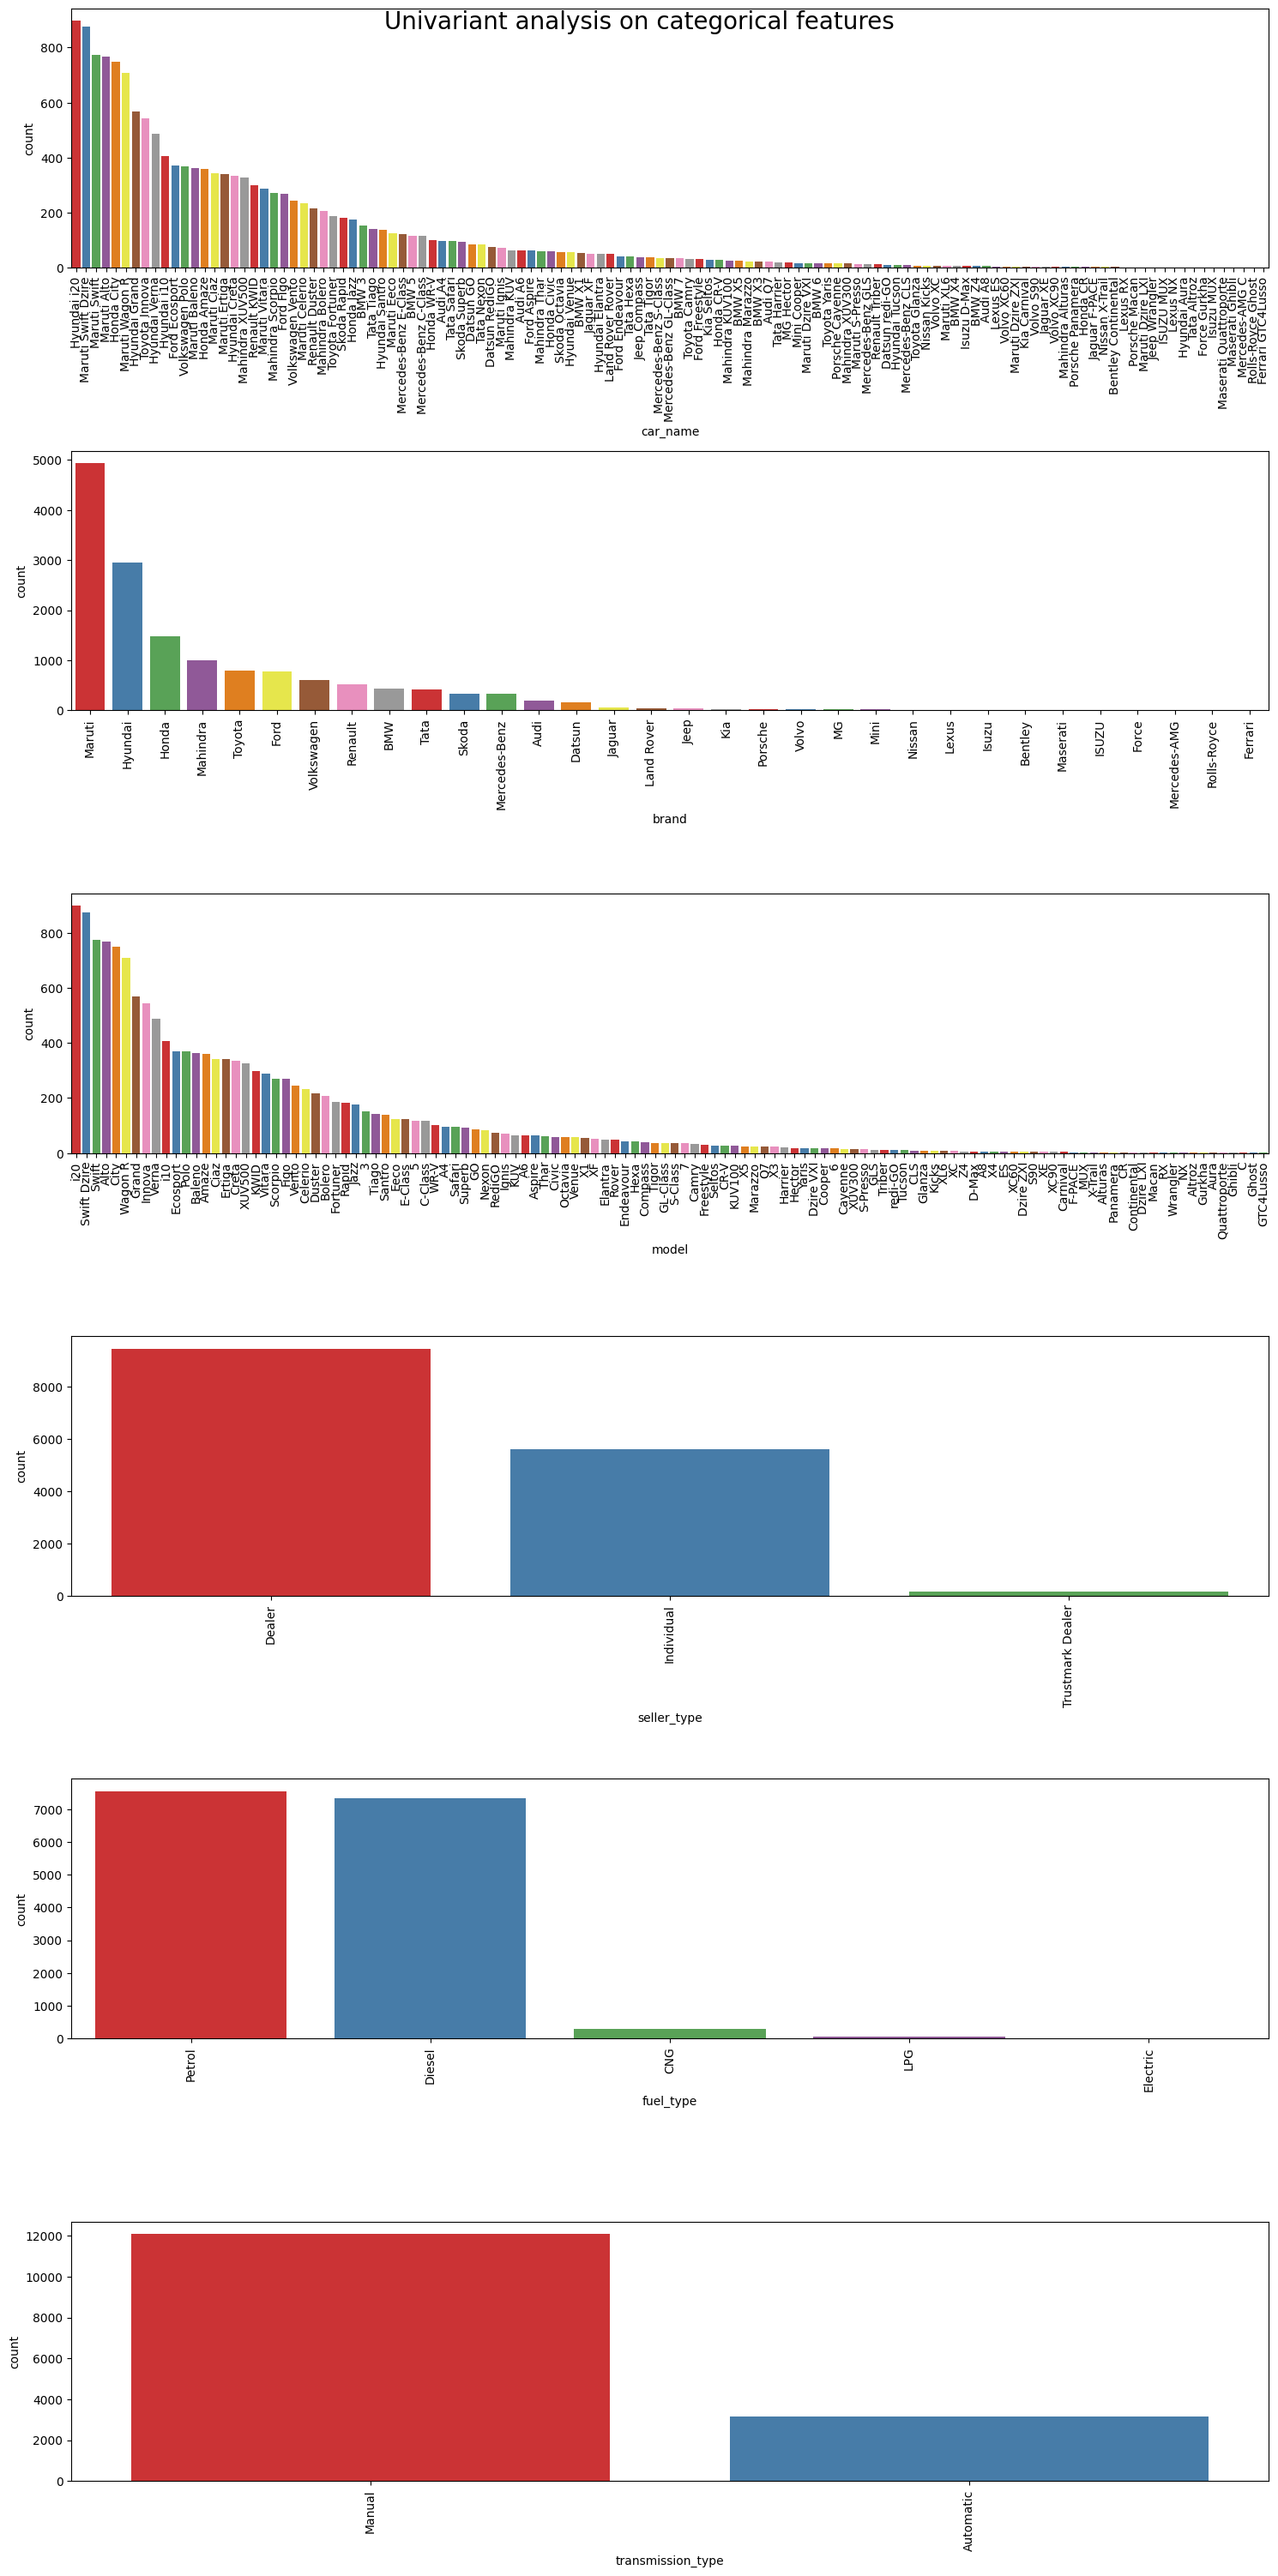

In [44]:
# Univariant Analysis
# categorical features

plt.figure(figsize=(15,30))
plt.suptitle("Univariant analysis on categorical features", fontsize=20)
for i in range(len(categorical_features)):
    plt.subplot(6,1,i+1)
    sns.countplot(x = df[categorical_features[i]],order= df[categorical_features[i]].value_counts().index, palette="Set1")
    plt.tight_layout()
    plt.xticks(rotation=90)

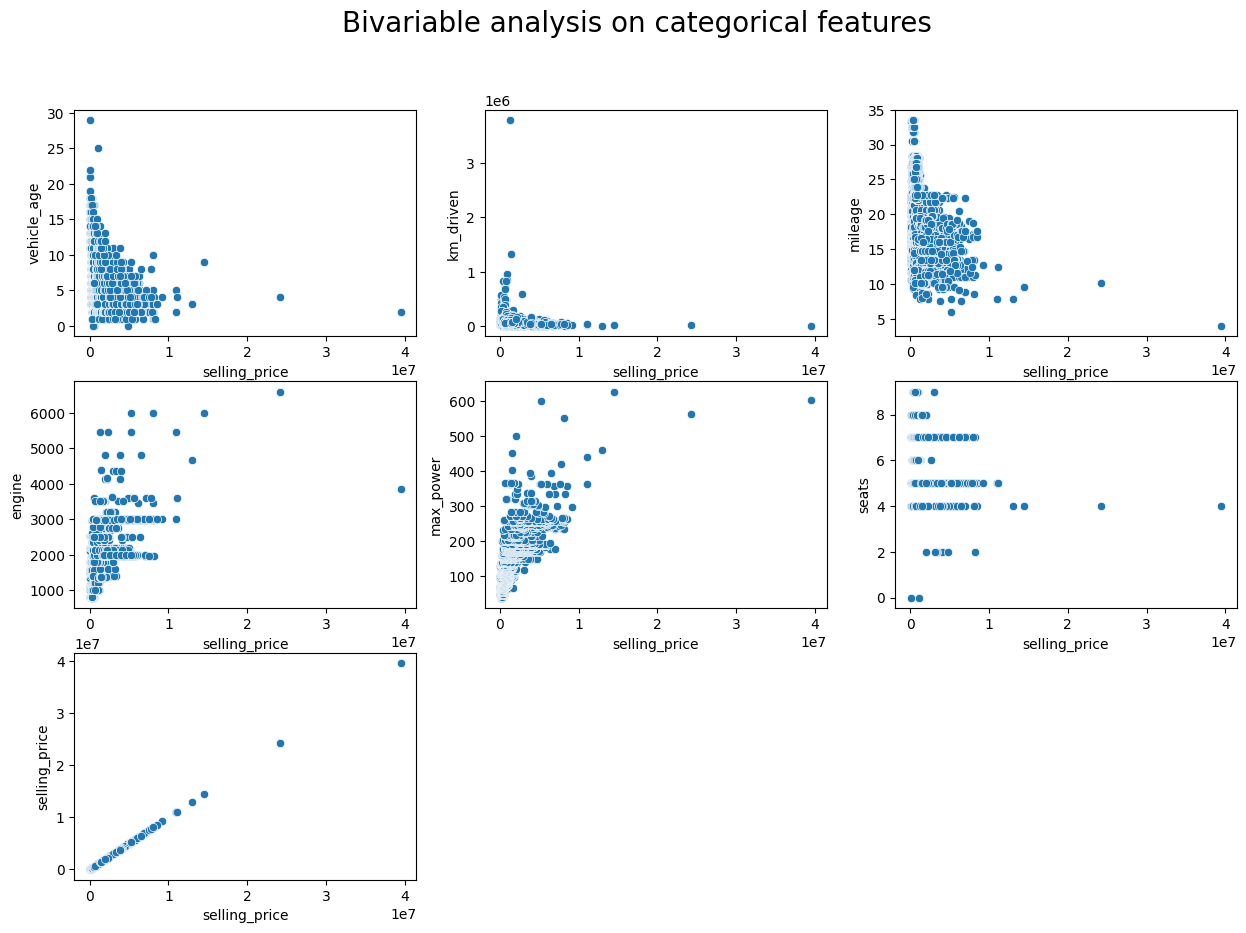

In [45]:
#Bivariable analysis 

plt.figure(figsize=(15,10))
plt.suptitle("Bivariable analysis on categorical features", fontsize=20)
for i in range(len(numerical_features)):
    plt.subplot(3,3,i+1)
    sns.scatterplot(x=df["selling_price"],y=df[numerical_features[i]])


<Axes: >

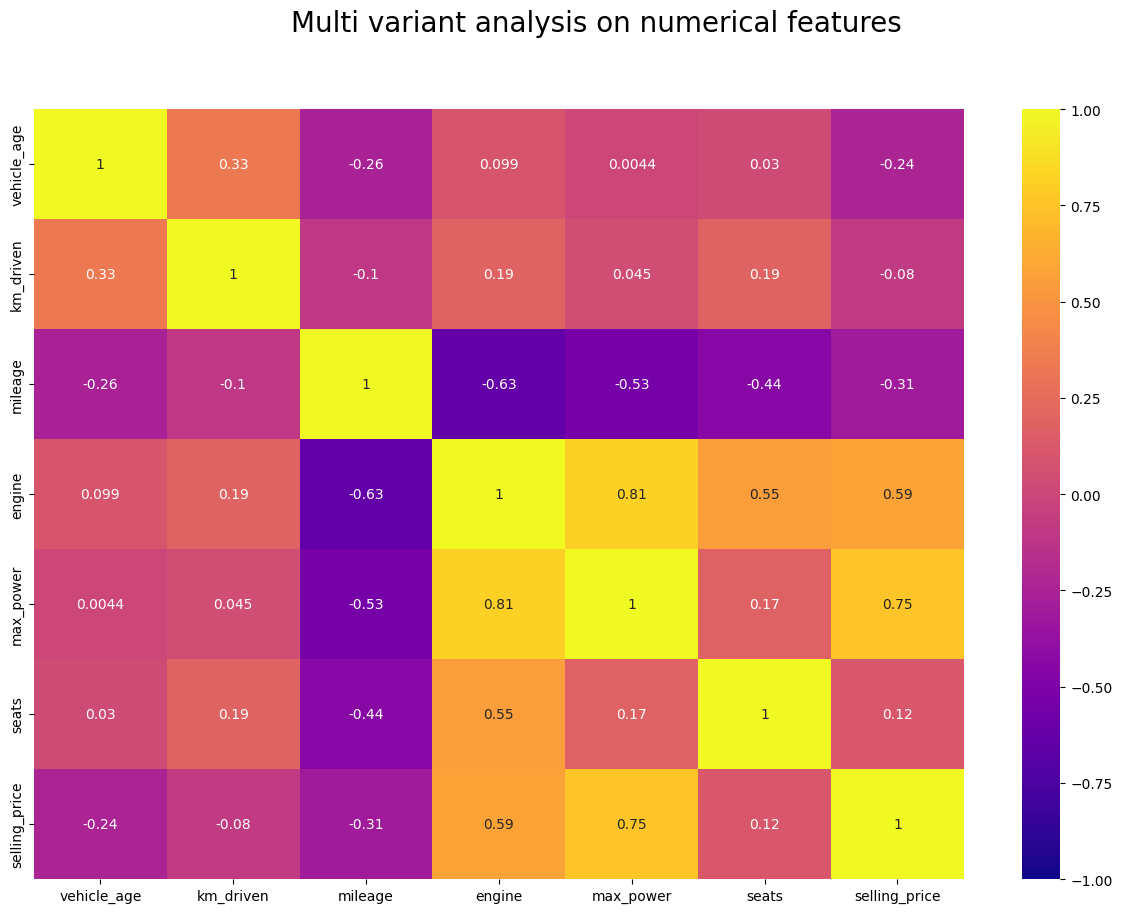

In [46]:
# Multi variant


plt.figure(figsize=(15,10))
plt.suptitle("Multi variant analysis on numerical features", fontsize=20)
sns.heatmap(df[numerical_features].corr(), annot=True, vmin=-1, vmax=+1, cmap="plasma")

 data visualisation
 

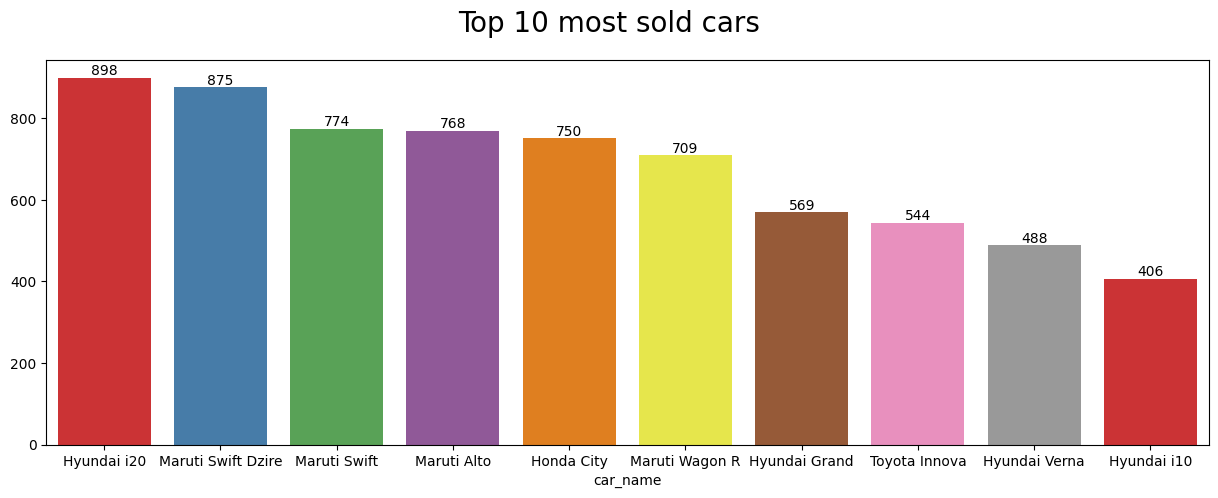

In [47]:

plt.figure(figsize=(15,5))
plt.suptitle("Top 10 most sold cars", fontsize=20)
top_10_cars = df['car_name'].value_counts().head(10)

ax = sns.barplot(x=top_10_cars.index, y=top_10_cars.values, palette="Set1")


for i in range(len(top_10_cars)):
    plt.bar_label(ax.containers[i], label_type='edge')

In [48]:
def formatted_values(value):
    if value >= 10000000:
        return f"{value/10000000:.2f} Crores"
    
    elif value >= 100000:
        return f"{value/100000:.2f} Lakhs"
    
    elif value >=1000:
        return f"{value/1000:.2f} K"
    
    else:
        return str(int(value))

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Ferrari GTC4Lusso'),
  Text(1, 0, 'Rolls-Royce Ghost'),
  Text(2, 0, 'Bentley Continental'),
  Text(3, 0, 'Mercedes-Benz S-Class'),
  Text(4, 0, 'Porsche Cayenne'),
  Text(5, 0, 'Land Rover Rover'),
  Text(6, 0, 'BMW 7'),
  Text(7, 0, 'BMW Z4'),
  Text(8, 0, 'Volvo XC'),
  Text(9, 0, 'BMW X5')])

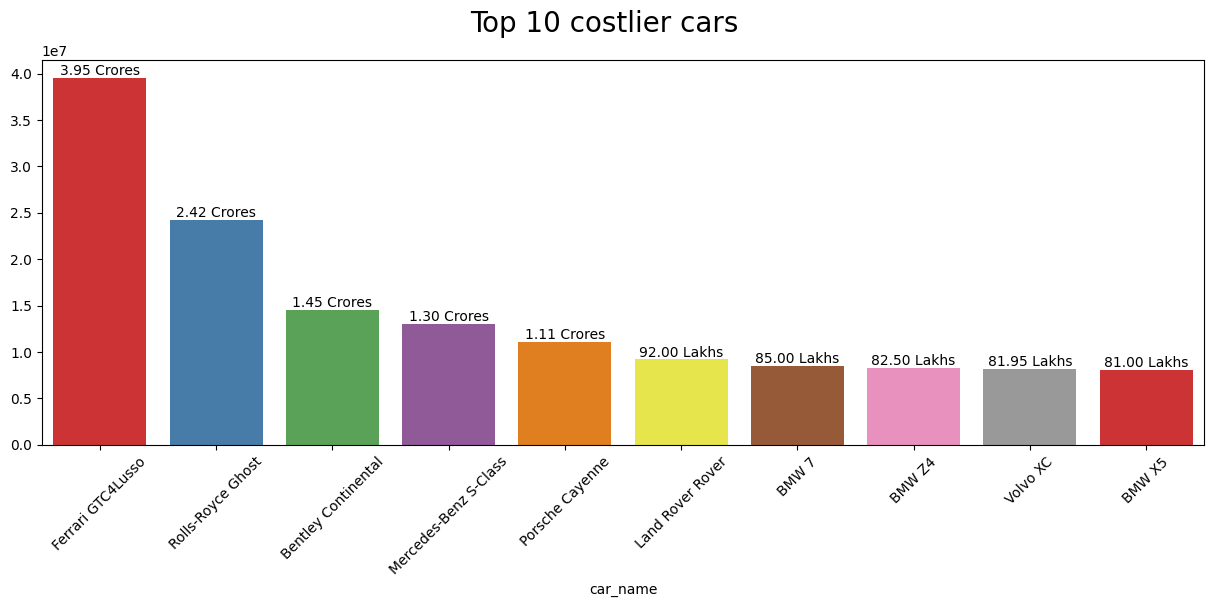

In [49]:
# top 10 most expensive cars in the dataset 
top_10_costlier_cars=df.groupby("car_name")['selling_price'].max().sort_values(ascending=False).head(10)
top_10_costlier_cars


plt.figure(figsize=(15,5))
plt.suptitle("Top 10 costlier cars", fontsize=20)


ax = sns.barplot(x=top_10_costlier_cars.index, y=top_10_costlier_cars.values, palette="Set1")

formatted_labels = [formatted_values(i) for i in top_10_costlier_cars.values]

for bar, label in zip(ax.containers, formatted_labels):
    plt.bar_label(container=bar, labels=[label], label_type='edge')

plt.xticks(rotation=45)

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'Ferrari'),
  Text(1, 0, 'Rolls-Royce'),
  Text(2, 0, 'Bentley'),
  Text(3, 0, 'Mercedes-Benz'),
  Text(4, 0, 'Porsche'),
  Text(5, 0, 'Land Rover'),
  Text(6, 0, 'BMW'),
  Text(7, 0, 'Volvo'),
  Text(8, 0, 'Lexus'),
  Text(9, 0, 'Audi')])

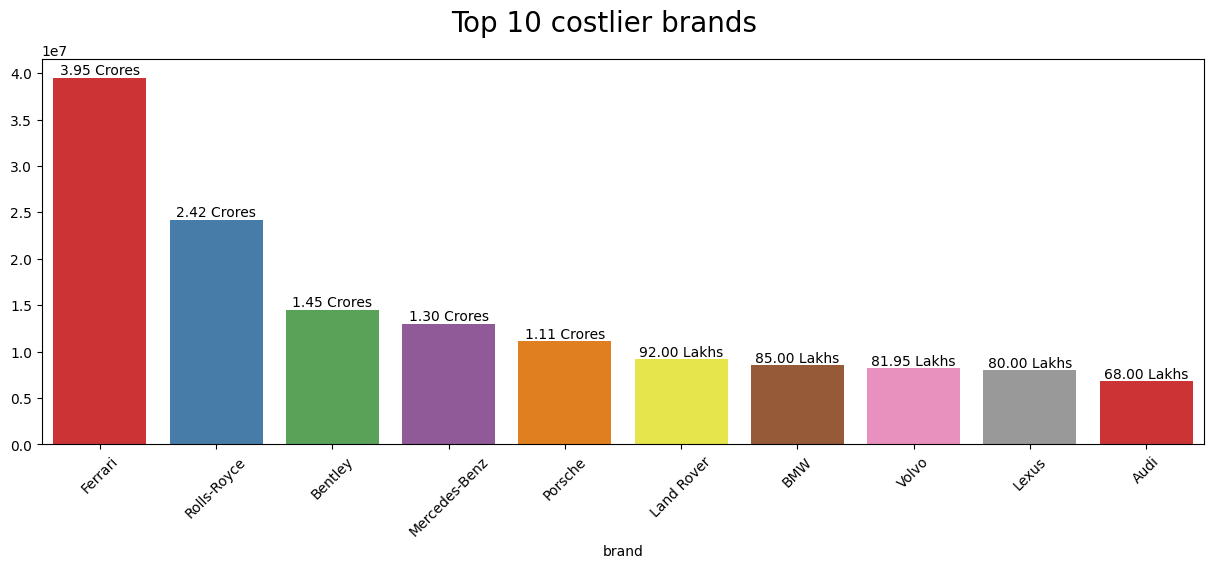

In [50]:
#top 10 costlier brand in dataset

top_10_costlier_brands = df.groupby("brand")['selling_price'].max().sort_values(ascending=False).head(10)
top_10_costlier_brands

plt.figure(figsize=(15,5))
plt.suptitle("Top 10 costlier brands", fontsize=20)


ax = sns.barplot(x=top_10_costlier_brands.index, y=top_10_costlier_brands.values, palette="Set1")

formatted_labels = [formatted_values(i) for i in top_10_costlier_brands.values]

for bar, label in zip(ax.containers, formatted_labels):
    plt.bar_label(container=bar, labels=[label], label_type='edge')

plt.xticks(rotation=45)

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
 [Text(0, 0, 'GTC4Lusso'),
  Text(1, 0, 'Ghost'),
  Text(2, 0, 'Continental'),
  Text(3, 0, 'S-Class'),
  Text(4, 0, 'Cayenne'),
  Text(5, 0, 'Rover'),
  Text(6, 0, '7'),
  Text(7, 0, 'Z4'),
  Text(8, 0, 'XC'),
  Text(9, 0, 'X5')])

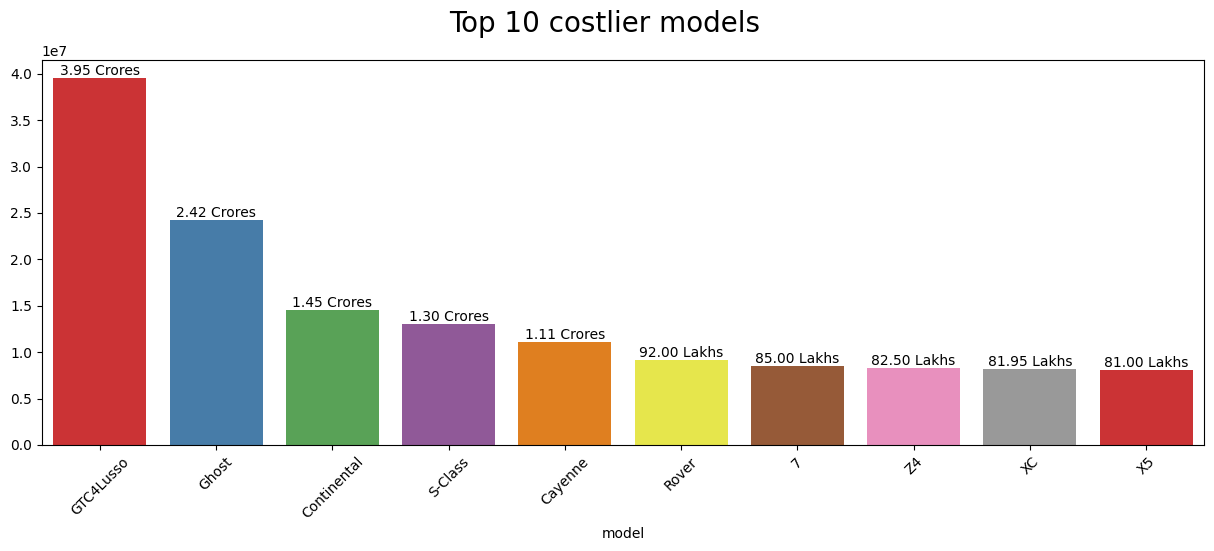

In [51]:
#top 10 costlier model in dataset

top_10_costlier_model = df.groupby("model")['selling_price'].max().sort_values(ascending=False).head(10)
top_10_costlier_model

plt.figure(figsize=(15,5))
plt.suptitle("Top 10 costlier models", fontsize=20)


ax = sns.barplot(x=top_10_costlier_model.index, y=top_10_costlier_model.values, palette="Set1")

formatted_labels = [formatted_values(i) for i in top_10_costlier_model.values]

for bar, label in zip(ax.containers, formatted_labels):
    plt.bar_label(container=bar, labels=[label], label_type='edge')

plt.xticks(rotation=45)

In [52]:
#top 10 sold brand in dataset


In [53]:
# top 10 sold model in dataset

([0, 1, 2, 3, 4],
 [Text(0, 0, 'Petrol'),
  Text(1, 0, 'Diesel'),
  Text(2, 0, 'CNG'),
  Text(3, 0, 'LPG'),
  Text(4, 0, 'Electric')])

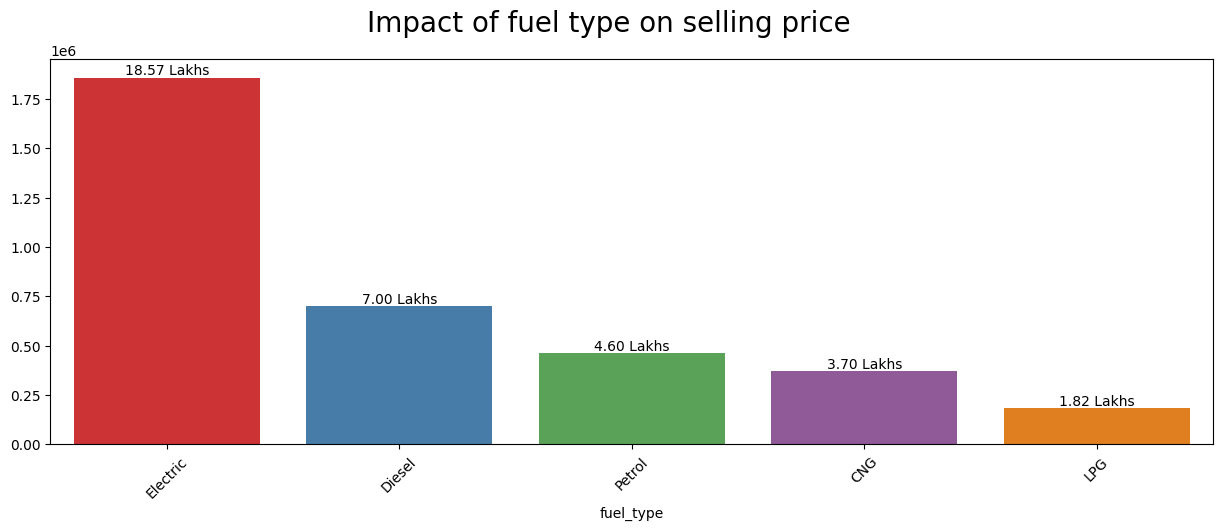

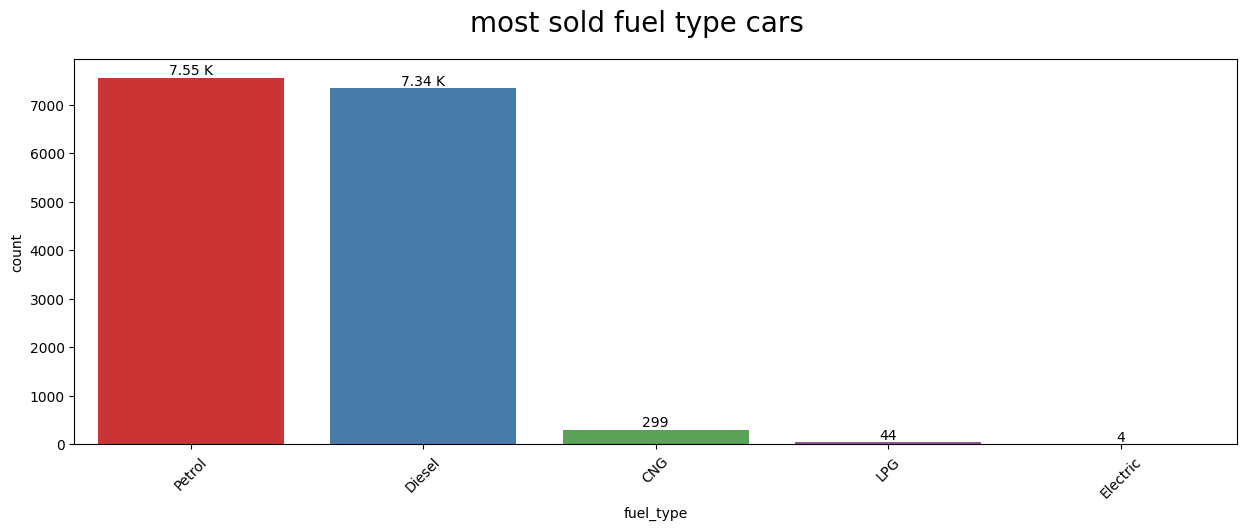

In [54]:
#Impact of fuel type on selling price 

selling_price_by_fuel=df.groupby("fuel_type")['selling_price'].median().sort_values(ascending=False)


plt.figure(figsize=(15,5))
plt.suptitle("Impact of fuel type on selling price ", fontsize=20)


ax = sns.barplot(x=selling_price_by_fuel.index, y=selling_price_by_fuel.values, palette="Set1")

formatted_labels = [formatted_values(i) for i in selling_price_by_fuel.values]

for bar, label in zip(ax.containers, formatted_labels):
    plt.bar_label(container=bar, labels=[label], label_type='edge')

plt.xticks(rotation=45)
# most sold fuel type cars


plt.figure(figsize=(15,5))
plt.suptitle("most sold fuel type cars", fontsize=20)


ax = sns.countplot(x=df['fuel_type'], palette="Set1", order=df['fuel_type'].value_counts().index)

formatted_labels = [formatted_values(i) for i in df['fuel_type'].value_counts().values]

for bar, label in zip(ax.containers, formatted_labels):
    plt.bar_label(container=bar, labels=[label], label_type='edge')

plt.xticks(rotation=45)

In [55]:
df.columns


Index(['car_name', 'brand', 'model', 'vehicle_age', 'km_driven', 'seller_type',
       'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power',
       'seats', 'selling_price'],
      dtype='object')

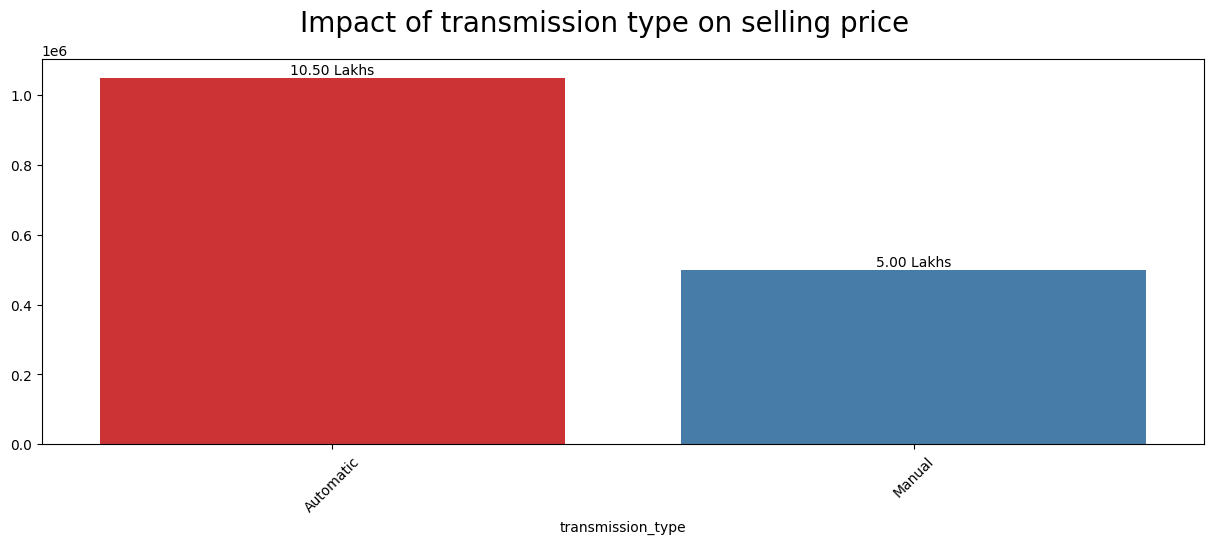

In [56]:
# impact of transmission type on selling price

selling_price_by_transmission = (
    df.groupby("transmission_type")['selling_price']
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(15,5))
plt.suptitle("Impact of transmission type on selling price", fontsize=20)

ax = sns.barplot(
    x=selling_price_by_transmission.index,
    y=selling_price_by_transmission.values,
    palette="Set1"
)

formatted_labels = [formatted_values(i) for i in selling_price_by_transmission.values]

for bar, label in zip(ax.containers, formatted_labels):
    plt.bar_label(container=bar, labels=[label], label_type='edge')

plt.xticks(rotation=45)
plt.show()

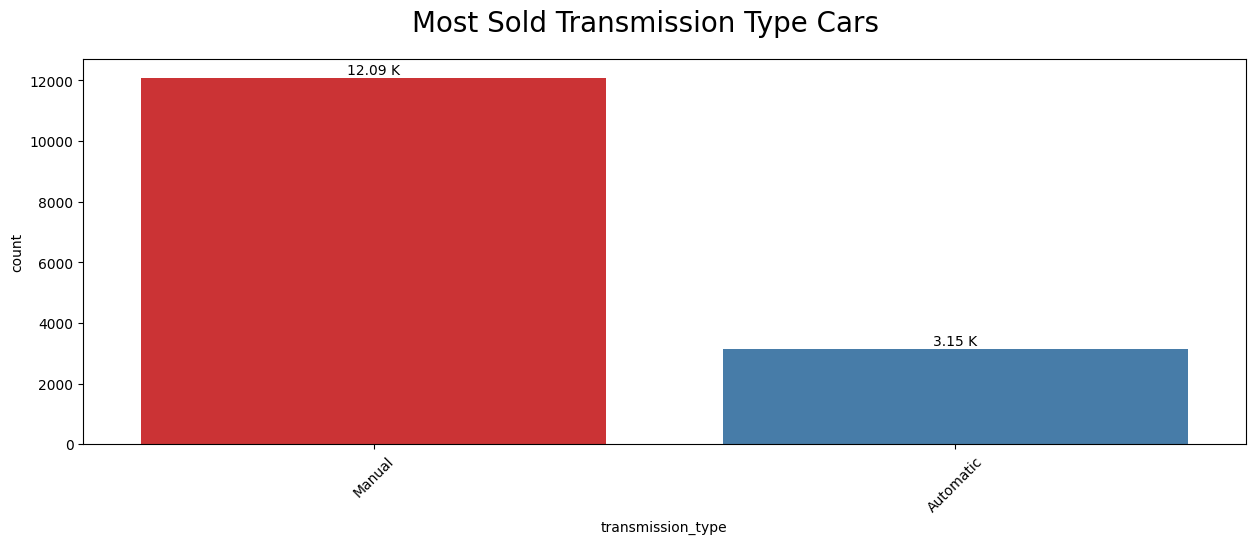

In [57]:
#most sold transmission type cars

plt.figure(figsize=(15,5))
plt.suptitle("Most Sold Transmission Type Cars", fontsize=20)

ax = sns.countplot(
    x=df['transmission_type'],
    palette="Set1",
    order=df['transmission_type'].value_counts().index
)

formatted_labels = [formatted_values(i) for i in df['transmission_type'].value_counts().values]

for bar, label in zip(ax.containers, formatted_labels):
    plt.bar_label(container=bar, labels=[label], label_type='edge')

plt.xticks(rotation=45)
plt.show()

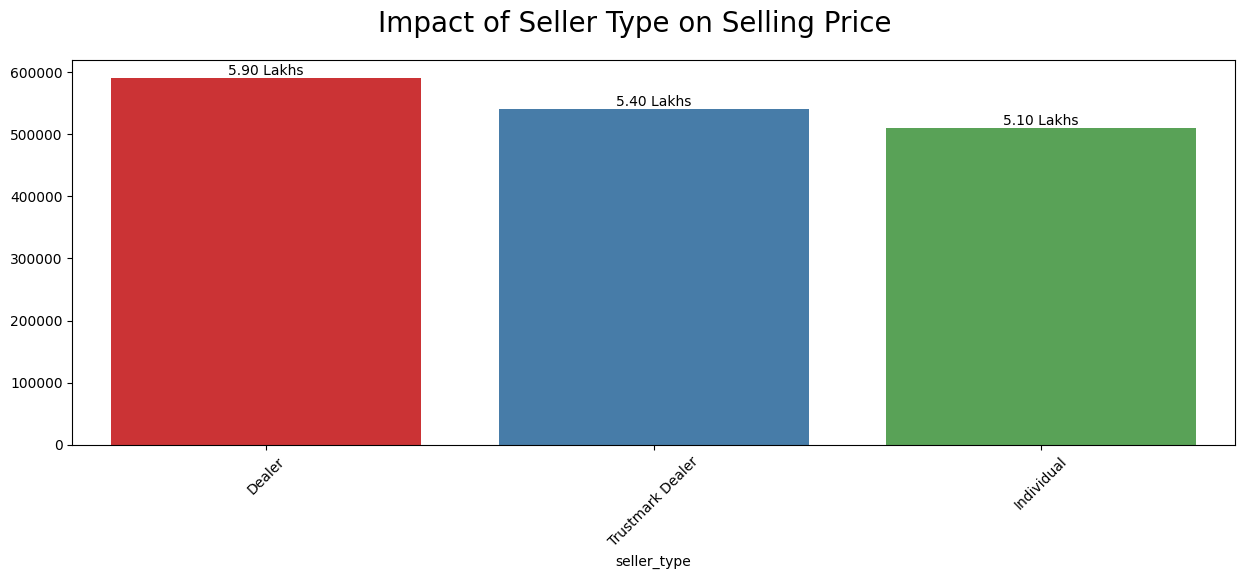

In [58]:
#impact of seller type on selling price 

selling_price_by_seller = (
    df.groupby("seller_type")['selling_price']
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(15,5))
plt.suptitle("Impact of Seller Type on Selling Price", fontsize=20)

ax = sns.barplot(
    x=selling_price_by_seller.index,
    y=selling_price_by_seller.values,
    palette="Set1"
)

formatted_labels = [formatted_values(i) for i in selling_price_by_seller.values]

for bar, label in zip(ax.containers, formatted_labels):
    plt.bar_label(container=bar, labels=[label], label_type='edge')

plt.xticks(rotation=45)
plt.show()

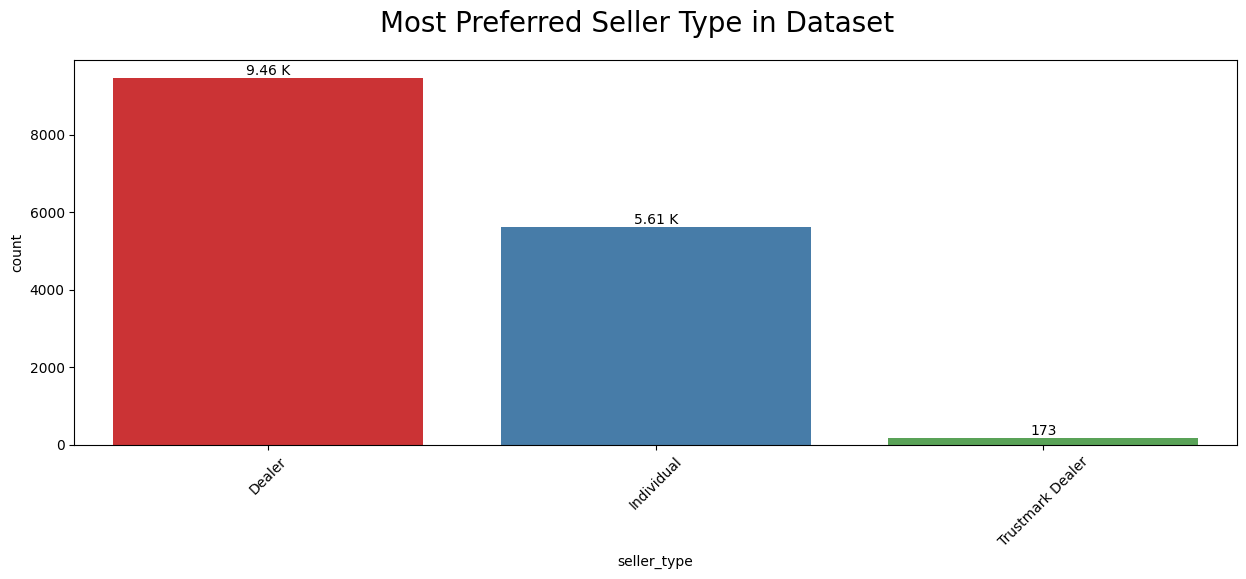

In [59]:
# most preferred seller type in dataset

plt.figure(figsize=(15,5))
plt.suptitle("Most Preferred Seller Type in Dataset", fontsize=20)

ax = sns.countplot(
    x='seller_type',
    data=df,
    order=df['seller_type'].value_counts().index,
    palette='Set1'
)

formatted_labels = [formatted_values(i) for i in df['seller_type'].value_counts().values]

for bar, label in zip(ax.containers, formatted_labels):
    plt.bar_label(container=bar, labels=[label], label_type='edge')

plt.xticks(rotation=45)
plt.show()

Final report

- there are outlines in engine,selling_price,max_power,vehicle_age,

Feature enguineering 


In [60]:
df_model = pd.read_csv("./data/cleaned_cars_dataset.csv")
df_model

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti Alto,Maruti,Alto,9,53800,Dealer,CNG,Manual,26.83,796,38.4,5,235000.0
1,Maruti Alto,Maruti,Alto,11,11000,Dealer,CNG,Manual,26.83,796,38.4,5,185000.0
2,Maruti Alto,Maruti,Alto,11,80000,Dealer,CNG,Manual,26.83,796,38.4,5,150000.0
3,Maruti Alto,Maruti,Alto,10,57000,Dealer,CNG,Manual,26.83,796,38.4,5,172000.0
4,Maruti Alto,Maruti,Alto,11,72000,Individual,CNG,Manual,26.83,796,38.4,5,125000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
15239,Bentley Continental,Bentley,Continental,10,30000,Dealer,Petrol,Automatic,8.60,5998,552.0,4,8100000.0
15240,Rolls-Royce Ghost,Rolls-Royce,Ghost,4,5000,Individual,Petrol,Automatic,10.20,6592,563.0,4,24200000.0
15241,Bentley Continental,Bentley,Continental,9,37500,Dealer,Petrol,Automatic,6.00,5998,600.0,5,5200000.0
15242,Ferrari GTC4Lusso,Ferrari,GTC4Lusso,2,3800,Dealer,Petrol,Automatic,4.00,3855,601.0,4,39500000.0


In [61]:
df_model

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti Alto,Maruti,Alto,9,53800,Dealer,CNG,Manual,26.83,796,38.4,5,235000.0
1,Maruti Alto,Maruti,Alto,11,11000,Dealer,CNG,Manual,26.83,796,38.4,5,185000.0
2,Maruti Alto,Maruti,Alto,11,80000,Dealer,CNG,Manual,26.83,796,38.4,5,150000.0
3,Maruti Alto,Maruti,Alto,10,57000,Dealer,CNG,Manual,26.83,796,38.4,5,172000.0
4,Maruti Alto,Maruti,Alto,11,72000,Individual,CNG,Manual,26.83,796,38.4,5,125000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
15239,Bentley Continental,Bentley,Continental,10,30000,Dealer,Petrol,Automatic,8.60,5998,552.0,4,8100000.0
15240,Rolls-Royce Ghost,Rolls-Royce,Ghost,4,5000,Individual,Petrol,Automatic,10.20,6592,563.0,4,24200000.0
15241,Bentley Continental,Bentley,Continental,9,37500,Dealer,Petrol,Automatic,6.00,5998,600.0,5,5200000.0
15242,Ferrari GTC4Lusso,Ferrari,GTC4Lusso,2,3800,Dealer,Petrol,Automatic,4.00,3855,601.0,4,39500000.0


In [62]:
df_model = df_model.drop(['brand', 'model', 'car_name'],axis=1)

In [63]:
df_model

,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,9,53800,Dealer,CNG,Manual,26.83,796,38.4,5,235000.0
1,11,11000,Dealer,CNG,Manual,26.83,796,38.4,5,185000.0
2,11,80000,Dealer,CNG,Manual,26.83,796,38.4,5,150000.0
3,10,57000,Dealer,CNG,Manual,26.83,796,38.4,5,172000.0
4,11,72000,Individual,CNG,Manual,26.83,796,38.4,5,125000.0
...,...,...,...,...,...,...,...,...,...,...
15239,10,30000,Dealer,Petrol,Automatic,8.60,5998,552.0,4,8100000.0
15240,4,5000,Individual,Petrol,Automatic,10.20,6592,563.0,4,24200000.0
15241,9,37500,Dealer,Petrol,Automatic,6.00,5998,600.0,5,5200000.0
15242,2,3800,Dealer,Petrol,Automatic,4.00,3855,601.0,4,39500000.0


In [64]:
df_model=pd.get_dummies(df_model, dtype=int)
df_model

,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price,seller_type_Dealer,seller_type_Individual,seller_type_Trustmark Dealer,fuel_type_CNG,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol,transmission_type_Automatic,transmission_type_Manual
0,9,53800,26.83,796,38.4,5,235000.0,1,0,0,1,0,0,0,0,0,1
1,11,11000,26.83,796,38.4,5,185000.0,1,0,0,1,0,0,0,0,0,1
2,11,80000,26.83,796,38.4,5,150000.0,1,0,0,1,0,0,0,0,0,1
3,10,57000,26.83,796,38.4,5,172000.0,1,0,0,1,0,0,0,0,0,1
4,11,72000,26.83,796,38.4,5,125000.0,0,1,0,1,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15239,10,30000,8.60,5998,552.0,4,8100000.0,1,0,0,0,0,0,0,1,1,0
15240,4,5000,10.20,6592,563.0,4,24200000.0,0,1,0,0,0,0,0,1,1,0
15241,9,37500,6.00,5998,600.0,5,5200000.0,1,0,0,0,0,0,0,1,1,0
15242,2,3800,4.00,3855,601.0,4,39500000.0,1,0,0,0,0,0,0,1,1,0


# Feature matrix(inpendent variable) and target(dependent variable)

In [65]:
X = df_model.drop("selling_price", axis=1)

In [66]:
X

,vehicle_age,km_driven,mileage,engine,max_power,seats,seller_type_Dealer,seller_type_Individual,seller_type_Trustmark Dealer,fuel_type_CNG,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol,transmission_type_Automatic,transmission_type_Manual
0,9,53800,26.83,796,38.4,5,1,0,0,1,0,0,0,0,0,1
1,11,11000,26.83,796,38.4,5,1,0,0,1,0,0,0,0,0,1
2,11,80000,26.83,796,38.4,5,1,0,0,1,0,0,0,0,0,1
3,10,57000,26.83,796,38.4,5,1,0,0,1,0,0,0,0,0,1
4,11,72000,26.83,796,38.4,5,0,1,0,1,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15239,10,30000,8.60,5998,552.0,4,1,0,0,0,0,0,0,1,1,0
15240,4,5000,10.20,6592,563.0,4,0,1,0,0,0,0,0,1,1,0
15241,9,37500,6.00,5998,600.0,5,1,0,0,0,0,0,0,1,1,0
15242,2,3800,4.00,3855,601.0,4,1,0,0,0,0,0,0,1,1,0


In [67]:
y = df_model.selling_price

In [68]:
y

0          235000.0
1          185000.0
2          150000.0
3          172000.0
4          125000.0
            ...    
15239     8100000.0
15240    24200000.0
15241     5200000.0
15242    39500000.0
15243    14500000.0
Name: selling_price, Length: 15244, dtype: float64

In [69]:
# train test split
from sklearn.model_selection import train_test_split
X_train,X_test, y_train, y_test= train_test_split(X,y, test_size=0.2, random_state=0)

In [70]:
X_train

,vehicle_age,km_driven,mileage,engine,max_power,seats,seller_type_Dealer,seller_type_Individual,seller_type_Trustmark Dealer,fuel_type_CNG,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol,transmission_type_Automatic,transmission_type_Manual
724,13,108000,17.30,1061,57.50,5,0,1,0,0,0,0,1,0,0,1
8920,5,77185,20.73,1373,91.10,5,1,0,0,0,0,0,0,1,0,1
3373,4,46139,24.00,1186,73.97,5,1,0,0,0,1,0,0,0,0,1
1259,6,70000,19.44,1198,67.00,7,0,1,0,0,0,0,0,1,0,1
12880,2,15200,17.00,1956,138.10,5,1,0,0,0,1,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13123,6,70000,16.00,2179,140.00,7,1,0,0,0,1,0,0,0,0,1
3264,7,89000,19.30,1248,73.90,5,1,0,0,0,1,0,0,0,0,1
9845,2,40000,26.10,1498,99.23,5,0,1,0,0,1,0,0,0,0,1
10799,3,40000,16.55,2498,105.00,6,0,1,0,0,1,0,0,0,0,1


In [71]:
X_test

,vehicle_age,km_driven,mileage,engine,max_power,seats,seller_type_Dealer,seller_type_Individual,seller_type_Trustmark Dealer,fuel_type_CNG,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol,transmission_type_Automatic,transmission_type_Manual
9253,6,66000,25.80,1498,98.60,5,1,0,0,0,1,0,0,0,0,1
787,6,36000,31.79,998,58.20,5,1,0,0,1,0,0,0,0,0,1
7265,4,58900,17.80,1198,86.70,5,0,1,0,0,0,0,0,1,0,1
3535,7,17205,16.47,1198,74.00,5,1,0,0,0,0,0,0,1,0,1
10031,5,139000,12.99,2494,100.60,8,0,1,0,0,1,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4782,9,47000,19.20,1197,80.00,5,1,0,0,0,0,0,0,1,1,0
2017,2,25000,23.95,998,67.05,5,0,1,0,0,0,0,0,1,1,0
11486,5,50000,17.80,1497,117.30,5,0,1,0,0,0,0,0,1,0,1
12009,2,17000,15.90,1496,120.69,5,1,0,0,0,0,0,0,1,0,1


In [72]:
y_train

724       175000.0
8920      600000.0
3373      375000.0
1259      350000.0
12880    1550000.0
           ...    
13123     915000.0
3264      565000.0
9845      650000.0
10799     850000.0
2732      180000.0
Name: selling_price, Length: 12195, dtype: float64

In [73]:
y_test

9253      415000.0
787       422000.0
7265      470000.0
3535      450000.0
10031    1150000.0
           ...    
4782      395000.0
2017      431000.0
11486     660000.0
12009     915000.0
11283     555000.0
Name: selling_price, Length: 3049, dtype: float64

In [74]:
df_model

,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price,seller_type_Dealer,seller_type_Individual,seller_type_Trustmark Dealer,fuel_type_CNG,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol,transmission_type_Automatic,transmission_type_Manual
0,9,53800,26.83,796,38.4,5,235000.0,1,0,0,1,0,0,0,0,0,1
1,11,11000,26.83,796,38.4,5,185000.0,1,0,0,1,0,0,0,0,0,1
2,11,80000,26.83,796,38.4,5,150000.0,1,0,0,1,0,0,0,0,0,1
3,10,57000,26.83,796,38.4,5,172000.0,1,0,0,1,0,0,0,0,0,1
4,11,72000,26.83,796,38.4,5,125000.0,0,1,0,1,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15239,10,30000,8.60,5998,552.0,4,8100000.0,1,0,0,0,0,0,0,1,1,0
15240,4,5000,10.20,6592,563.0,4,24200000.0,0,1,0,0,0,0,0,1,1,0
15241,9,37500,6.00,5998,600.0,5,5200000.0,1,0,0,0,0,0,0,1,1,0
15242,2,3800,4.00,3855,601.0,4,39500000.0,1,0,0,0,0,0,0,1,1,0


In [75]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [76]:
X_train_scaled

array([[ 2.3031794 ,  0.95739945, -0.57657397, ..., -0.98866611,
        -0.50652619,  0.50652619],
       [-0.35129002,  0.39097469,  0.24501592, ...,  1.01146382,
        -0.50652619,  0.50652619],
       [-0.6830987 , -0.17969619,  1.02828091, ..., -0.98866611,
        -0.50652619,  0.50652619],
       ...,
       [-1.34671606, -0.29253999,  1.53129513, ..., -0.98866611,
        -0.50652619,  0.50652619],
       [-1.01490738, -0.29253999, -0.7562219 , ..., -0.98866611,
        -0.50652619,  0.50652619],
       [ 1.97137073, -0.25577707,  0.02464778, ...,  1.01146382,
        -0.50652619,  0.50652619]], shape=(12195, 16))

In [77]:
X_test_scaled

array([[-0.01948135,  0.18537803,  1.45943595, ..., -0.98866611,
        -0.50652619,  0.50652619],
       [-0.01948135, -0.36606584,  2.89422412, ..., -0.98866611,
        -0.50652619,  0.50652619],
       [-0.6830987 ,  0.05486965, -0.45680868, ...,  1.01146382,
        -0.50652619,  0.50652619],
       ...,
       [-0.35129002, -0.10872537, -0.45680868, ...,  1.01146382,
        -0.50652619,  0.50652619],
       [-1.34671606, -0.71531363, -0.91191678, ...,  1.01146382,
        -0.50652619,  0.50652619],
       [-0.01948135, -0.57669902, -0.69633926, ...,  1.01146382,
        -0.50652619,  0.50652619]], shape=(3049, 16))

In [78]:
# checking important features

from sklearn.ensemble import ExtraTreesRegressor
model = ExtraTreesRegressor()
model.fit(X_train_scaled, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,False
,oob_score,False


<Axes: >

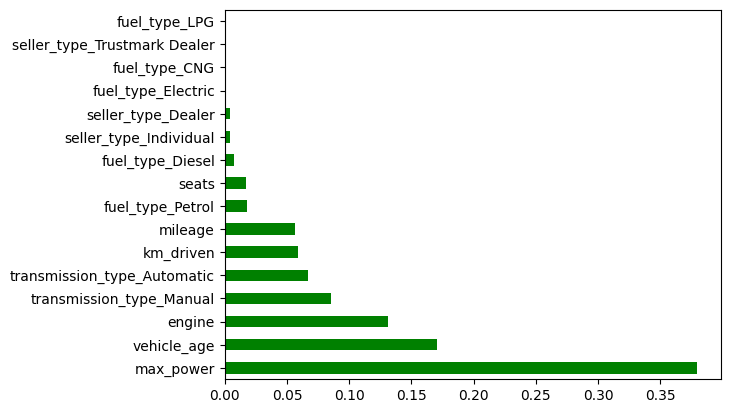

In [79]:
imp_features= pd.Series(model.feature_importances_, index=X_train.columns)
imp_features.nlargest(30).plot(kind="barh", color='g')

# Model building and evaluation


In [80]:
# 2 20000 20.5 => 700000
# 4 45000 15.5 => 500000
# 5 50000 18.5 => 300000

# test => 3 15000 19.5 => ? 5-7l => 5.5l => 5.3 => 20k error =>  95%


from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

In [81]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, explained_variance_score, r2_score

models = [LinearRegression, Ridge, Lasso,SVR, DecisionTreeRegressor, RandomForestRegressor]

mae = []
mse = []
rmse = []
evs = []
r_squared_score =[] # accuracy


for model in models:
    regressor = model().fit(X_train_scaled, y_train)
    y_pred = regressor.predict(X_test_scaled)
    print(y_pred)

    mae.append(mean_absolute_error(y_true=y_test, y_pred=y_pred))
    mse.append(mean_squared_error(y_true=y_test, y_pred=y_pred))
    rmse.append(np.sqrt(mean_squared_error(y_true=y_test, y_pred=y_pred)))
    evs.append(explained_variance_score(y_true=y_test, y_pred=y_pred))
    r_squared_score.append(r2_score(y_true=y_test, y_pred=y_pred))


[ 804303.62703048  389608.6097706   607937.565964   ... 1029213.61331539
 1268263.6409822   955897.78927778]
[ 804283.89125159  389582.53406114  607921.03099459 ... 1029136.54490109
 1268203.68854655  955850.12517406]
[ 804301.5250597   389593.61566031  607939.21288103 ... 1029211.02821784
 1268266.48833189  955898.80299049]
[555613.01848716 555633.7169583  554894.41616759 ... 555044.59625017
 555560.81920181 555123.71442854]
[388000. 435000. 440000. ... 600000. 925000. 490000.]
[409835.  402330.  548230.  ... 679062.5 976500.  673940. ]


In [82]:
ml_models_df = pd.DataFrame({
    'Models': ["LinearRegression", "Ridge", "Lasso","SVR", "DecisionTreeRegressor", "RandomForestRegressor"],
    'mean_absolute_error':mae,
    'mean_squared_error':mse,
    "root_mean_squared_error":rmse,
    "explained_variance_score":evs,
    "r2_score":r_squared_score
})

ml_models_df.set_index("Models", inplace=True)
ml_models_df

,mean_absolute_error,mean_squared_error,root_mean_squared_error,explained_variance_score,r2_score
Models,,,,,
LinearRegression,272203.174744,2.542605e+11,504242.530165,0.693637,0.693503
Ridge,272189.182129,2.542683e+11,504250.213608,0.693628,0.693494
Lasso,272202.706260,2.542608e+11,504242.793634,0.693637,0.693503
SVR,426403.311656,8.894944e+11,943130.129852,0.000783,-0.072236
DecisionTreeRegressor,131266.781458,1.020617e+11,319470.936658,0.877081,0.876970
RandomForestRegressor,104332.989703,5.362571e+10,231572.245904,0.935369,0.935357


In [88]:
   # define tune params

params_grid = {LinearRegression:{},
    Ridge:{
        'alpha':[0.1,1.0,10.0]
    },
    Lasso:{
        'alpha':[0.001,0.01,0.1,1.0]
    },
    SVR:{
        'kernel':['rbf', 'linear'],
        'C':[0.1,1,10],
        'epsilon':[0.01,0.1,0.5]
    },
    DecisionTreeRegressor:{
        'max_depth':[None,5,10,20],
        'min_samples_split':[2,5,10]
    },
    
    RandomForestRegressor:{
        'n_estimators':[50,100,200],
        'max_depth':[None,5,10,20],
        'min_samples_split':[2,5,10]
    }
}

# metrics_list

models = [LinearRegression, Ridge, Lasso,SVR, DecisionTreeRegressor, RandomForestRegressor]

mae = []
mse = []
rmse = []
evs = []
r_squared_score =[] # accuracy
best_models = []


for model in models:
    print(f"Tuning:{model.__name__}")

    if params_grid[model]:
        grid = GridSearchCV(model(), param_grid=params_grid[model], cv=5,scoring='r2',n_jobs=-1)
        grid.fit(X_train_scaled,y_train)
        regressor= grid.best_estimator_
        print(f"Best Params:{grid.best_params_}")

    else:
        regressor = model().fit(X_train_scaled, y_train)

    y_pred = regressor.predict(X_test_scaled)

    print(y_pred)

    mae.append(mean_absolute_error(y_true=y_test, y_pred=y_pred))
    mse.append(mean_squared_error(y_true=y_test, y_pred=y_pred))
    rmse.append(np.sqrt(mean_squared_error(y_true=y_test, y_pred=y_pred)))
    evs.append(explained_variance_score(y_true=y_test, y_pred=y_pred))
    r_squared_score.append(r2_score(y_true=y_test, y_pred=y_pred))
    best_models.append(regressor)

Tuning:LinearRegression
[ 804303.62703048  389608.6097706   607937.565964   ... 1029213.61331539
 1268263.6409822   955897.78927778]
Tuning:Ridge
Best Params:{'alpha': 10.0}
[ 804104.72030578  389345.20533382  607773.20059969 ... 1028444.69320465
 1267665.52186151  955422.4020015 ]
Tuning:Lasso
Best Params:{'alpha': 1.0}
[ 804301.5250597   389593.61566031  607939.21288103 ... 1029211.02821784
 1268266.48833189  955898.80299049]
Tuning:SVR
Best Params:{'C': 10, 'epsilon': 0.5, 'kernel': 'linear'}
[596081.18284243 386182.11433544 497882.0671705  ... 542822.67190071
 641596.23320941 561454.73238619]
Tuning:DecisionTreeRegressor
Best Params:{'max_depth': 20, 'min_samples_split': 2}
[388000. 435000. 479000. ... 600000. 925000. 490000.]
Tuning:RandomForestRegressor
Best Params:{'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}
[530991.51446965 339192.46315747 522372.59617263 ... 723161.11197495
 983070.17448008 692269.52105264]


In [84]:
from sklearn.model_selection import GridSearchCV

In [85]:
# define tune params

params_grid = {
    LinearRegression:{},
    Ridge:{
        'alpha':[0.1,1.0,10.0]
    },
    Lasso:{
        'alpha':[0.001,0.01,0.1,1.0]
    },
    SVR:{
        'kernel':['rbf', 'linear'],
        'C':[0.1,1,10],
        'epsilon':[0.01,0.1,0.5]
    },
    DecisionTreeRegressor:{
        'max_depth':[None,5,10,20],
        'min_samples_split':[2,5,10]
    },
    
    RandomForestRegressor:{
        'n_estimators':[50,100,200],
        'max_depth':[None,5,10,20],
        'min_samples_split':[2,5,10]
    }
}

# metrics_list

models = [LinearRegression, Ridge, Lasso,SVR, DecisionTreeRegressor, RandomForestRegressor]

mae = []
mse = []
rmse = []
evs = []
r_squared_score =[] # accuracy
best_models = []


for model in models:
    print(f"Tuning:{model.__name__}")

    if params_grid[model]:
        grid = GridSearchCV(model(), param_grid=params_grid[model], cv=5,scoring='r2',n_jobs=-1)
        grid.fit(X_train_scaled,y_train)
        regressor= grid.best_estimator_
        print(f"Best Params:{grid.best_params_}")

    else:
        regressor = model().fit(X_train_scaled, y_train)

    y_pred = regressor.predict(X_test_scaled)

    print(y_pred)

    mae.append(mean_absolute_error(y_true=y_test, y_pred=y_pred))
    mse.append(mean_squared_error(y_true=y_test, y_pred=y_pred))
    rmse.append(np.sqrt(mean_squared_error(y_true=y_test, y_pred=y_pred)))
    evs.append(explained_variance_score(y_true=y_test, y_pred=y_pred))
    r_squared_score.append(r2_score(y_true=y_test, y_pred=y_pred))
    best_models.append(regressor)

Tuning:LinearRegression
[ 804303.62703048  389608.6097706   607937.565964   ... 1029213.61331539
 1268263.6409822   955897.78927778]
Tuning:Ridge
Best Params:{'alpha': 10.0}
[ 804104.72030578  389345.20533382  607773.20059969 ... 1028444.69320465
 1267665.52186151  955422.4020015 ]
Tuning:Lasso
Best Params:{'alpha': 1.0}
[ 804301.5250597   389593.61566031  607939.21288103 ... 1029211.02821784
 1268266.48833189  955898.80299049]
Tuning:SVR
Best Params:{'C': 10, 'epsilon': 0.5, 'kernel': 'linear'}
[596081.18284243 386182.11433544 497882.0671705  ... 542822.67190071
 641596.23320941 561454.73238619]
Tuning:DecisionTreeRegressor
Best Params:{'max_depth': 10, 'min_samples_split': 2}
[458400.         348172.89719626 516500.         ... 711559.60264901
 949120.68965517 578006.84931507]
Tuning:RandomForestRegressor
Best Params:{'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 100}
[ 527564.14602019  336828.47135929  522833.15419566 ...  721599.16643208
 1000578.90879317  687711.8136429

In [86]:
ml_models_df = pd.DataFrame({
    'Models': ["LinearRegression", "Ridge", "Lasso","SVR", "DecisionTreeRegressor", "RandomForestRegressor"],
    'mean_absolute_error':mae,
    'mean_squared_error':mse,
    "root_mean_squared_error":rmse,
    "explained_variance_score":evs,
    "r2_score":r_squared_score
})

ml_models_df.set_index("Models", inplace=True)
ml_models_df

,mean_absolute_error,mean_squared_error,root_mean_squared_error,explained_variance_score,r2_score
Models,,,,,
LinearRegression,272203.174744,2.542605e+11,504242.530165,0.693637,0.693503
Ridge,272063.871015,2.543387e+11,504319.998069,0.693544,0.693409
Lasso,272202.706260,2.542608e+11,504242.793634,0.693637,0.693503
SVR,324486.366293,6.664993e+11,816394.091798,0.247021,0.196572
DecisionTreeRegressor,131970.435945,2.727677e+11,522271.665056,0.671196,0.671194
RandomForestRegressor,110898.262781,5.864182e+10,242160.734457,0.929346,0.929311


In [87]:
best_models

[LinearRegression(),
 Ridge(alpha=10.0),
 Lasso(),
 SVR(C=10, epsilon=0.5, kernel='linear'),
 DecisionTreeRegressor(max_depth=10),
 RandomForestRegressor(max_depth=10)]

# Importing and saving the best model 


In [89]:
import pickle

model_save_dir = "./saved_models/"
os.makedirs(model_save_dir, exist_ok=True)

for model in best_models:
    model_name = type(model).__name__
    model.fit(X_train_scaled, y_train)

    filename = f"{model_name}.pkl"

    print(f"Saving: {filename}")

    model_path = os.path.join(model_save_dir, filename)

    with open(model_path, 'wb') as f:
        pickle.dump(model, f)
    
    print(f"Successfully Trained and Saved :{filename}")

Saving: LinearRegression.pkl
Successfully Trained and Saved :LinearRegression.pkl
Saving: Ridge.pkl
Successfully Trained and Saved :Ridge.pkl
Saving: Lasso.pkl
Successfully Trained and Saved :Lasso.pkl
Saving: SVR.pkl
Successfully Trained and Saved :SVR.pkl
Saving: DecisionTreeRegressor.pkl
Successfully Trained and Saved :DecisionTreeRegressor.pkl
Saving: RandomForestRegressor.pkl
Successfully Trained and Saved :RandomForestRegressor.pkl


In [90]:
os.makedirs("./saved_scaling/", exist_ok=True)

with open("./saved_scaling/scaler.pkl", "wb") as f:
    pickle.dump(scaler,f)

# Loding the best Model 


In [91]:
model_path = "./saved_models/RandomForestRegressor.pkl"

with open(model_path, 'rb') as f:
    model = pickle.load(f)

In [92]:
model

,n_estimators,100
,criterion,'squared_error'
,max_depth,10
,min_samples_split,5
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [93]:
model.score(X_train_scaled,y_train)

0.9457240964736524

In [94]:
model.score(X_test_scaled, y_test )

0.9291095872688723

#  Hence random forest is generalised model